# SD-147 · Urban air quality

A synthetic year of Metro Manila air, drawn so the pictures are obvious.

Twelve stations, every hour of 2024, six pollutants, and the weather that moved them. Roadside EDSA and upland Antipolo share the year and do not share a color. The grey week and the teal stripe on the calendar are not noise. They were written in on purpose.

| | |
| --- | --- |
| Project | **SD-147** · Synthetic Dataset · Government & Public Services |
| For | an urban-services analyst who has to decide where a bad-air day is real |
| Scope | difficulty 1, a single airshed |
| Seed | `147`, so Run All reproduces the CSVs byte for byte |

The generator is `src/aq_model.py`. Every coefficient, breakpoint, and planted event is written out in `assumptions.md`. This notebook is the run, the check, and the pictures.


## How the air is made

Concentrations are lognormal. Underneath the log is a station baseline, a morning and evening traffic wave, a dry-season cosine that peaks in early February, and two slow shocks so a dirty hour is usually followed by another one.

Rain washes particles out. Wind disperses them, with diminishing returns once it is already blowing hard. Ozone does the opposite of the traffic gases: it rises toward 14:00, and it is lower wherever fresh NO2 is high. That is why Antipolo, which has little traffic and sits about 200 metres above the basin, is the ozone station, and EDSA is the particle station.

PM10 is not a separate invention. It is PM2.5 plus coarse dust, and the code refuses to let it fall below the fine fraction.

Four events are not random draws.

1. **Fireworks** on the morning of 1 January, the evening of Chinese New Year (10 February), and the evening of 31 December. Fine smoke. The PM2.5/PM10 ratio climbs.
2. **Construction dust** at Valenzuela, weekday work hours, 4–15 March. PM10 jumps by about 115 µg/m³. The gases do not.
3. **A frozen sensor** at EDSA, 12–18 August. PM2.5 and PM10 hold one number and carry the flag `sensor_fault`. Ozone and NO2 keep reporting.
4. **A typhoon** from 15 September 06:00 to 17 September 18:00. Rain, wind, and a drop in every pollutant. It is a synthetic system, not a reconstruction of a named storm.

About 0.4% of the remaining hours are ordinary telemetry gaps. The calendar colors a day's mean PM2.5 with the US EPA 24-hour breakpoints. Alerts use a trailing 24-hour mean for particles, 8 hours for ozone and CO, and the hour itself for NO2 and SO2. An episode starts at index 101. None of this is a DENR determination.


## Generate the five tables


In [1]:
from pathlib import Path
import sys

import pandas as pd

ROOT = Path.cwd().resolve()
for candidate in [ROOT, *ROOT.parents]:
    if (candidate / "src" / "aq_model.py").exists():
        ROOT = candidate
        break
sys.path.insert(0, str(ROOT))

from src.aq_model import SEED, generate, sanity_report
from src.aq_plots import (
    apply_style,
    calendars,
    diurnal,
    episodes,
    season_grid,
    station_map,
    washout,
)

apply_style()
pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 120)

tables = generate(SEED)
data_dir = ROOT / "data"
data_dir.mkdir(exist_ok=True)
for name, frame in tables.items():
    frame.to_csv(data_dir / f"{name}.csv", index=False)

summary = pd.DataFrame(
    {
        "table": list(tables),
        "rows": [len(frame) for frame in tables.values()],
        "columns": [frame.shape[1] for frame in tables.values()],
    }
)
summary


,table,rows,columns
0,stations,12,10
1,pollutants,6,6
2,readings,632448,6
3,weather_proxies,105408,9
4,alerts,749,9


In [2]:
tables["stations"]


,station_id,station_name,city,district,station_type,latitude,longitude,elevation_m,commissioned_on,operator
0,STA-EDSA,EDSA–Guadalupe,Makati,Guadalupe,roadside,14.5667,121.0456,18,2016-03-01,Synthetic Metro Manila Airshed
1,STA-QCH,Quezon City Hall,Quezon City,Diliman,urban background,14.6488,121.0509,32,2014-07-15,Synthetic Metro Manila Airshed
2,STA-MNL,Manila City Hall,Manila,Ermita,urban center,14.5896,120.9816,10,2013-01-20,Synthetic Metro Manila Airshed
3,STA-PRT,Manila Port,Manila,Tondo,industrial port,14.5831,120.9614,5,2015-11-02,Synthetic Metro Manila Airshed
4,STA-MKT,Makati CBD,Makati,Ayala,commercial roadside,14.5547,121.0244,18,2017-05-08,Synthetic Metro Manila Airshed
5,STA-PSG,Pasig Rotonda,Pasig,Caniogan,mixed roadside,14.5758,121.0851,16,2018-02-12,Synthetic Metro Manila Airshed
6,STA-MRK,Marikina Riverpark,Marikina,Santa Elena,valley residential,14.6507,121.1029,14,2018-09-01,Synthetic Metro Manila Airshed
7,STA-LPI,Las Piñas Coastal,Las Piñas,Pulanglupa,coastal background,14.4445,120.9939,8,2019-04-18,Synthetic Metro Manila Airshed
8,STA-VAL,Valenzuela Industrial,Valenzuela,Karuhatan,industrial,14.7004,120.9830,12,2015-06-22,Synthetic Metro Manila Airshed
9,STA-ANT,Antipolo Upland,Antipolo,San Roque,upland background,14.6255,121.2142,210,2019-10-09,Synthetic Metro Manila Airshed


In [3]:
tables["readings"].head(3)


,reading_id,station_id,pollutant_id,observed_at,value,quality_flag
0,1,STA-EDSA,PM25,2024-01-01 00:00:00,332.5,ok
1,2,STA-EDSA,PM25,2024-01-01 01:00:00,356.0,ok
2,3,STA-EDSA,PM25,2024-01-01 02:00:00,347.7,ok


## The world has to survive a check

Sixteen statements about ranges, correlations, and the four planted events. If one fails, the CSVs are not to be trusted and the notebook stops.


In [4]:
report = sanity_report(tables)
failed = report.loc[~report["passed"], "check"].tolist()
if failed:
    raise RuntimeError("Sanity checks failed: " + "; ".join(failed))
report


,check,passed,detail
0,no negative concentrations,True,min 0.05
1,PM10 always above PM2.5,True,"rows 104,445"
2,PM2.5 correlates with PM10,True,r = 0.96
3,rain washes PM2.5 down,True,daily r = -0.18; wet-day mean 22.9 vs dry-day ...
4,wind disperses PM2.5,True,daily r = -0.46
5,Sunday traffic is quieter,True,roadside NO2 weekday 58.2 vs Sunday 39.1
6,ozone peaks in the afternoon,True,14:00 mean 94.2 vs 06:00 29.4
7,daytime ozone and NO2 oppose each other,True,roadside 10:00–16:00 r = -0.64
8,upland station is cleaner than EDSA,True,Antipolo 11.5 vs EDSA 38.2
9,annual means sit in a Manila-like band,True,"{'STA-ANT': 11.5, 'STA-BGC': 20.7, 'STA-EDSA':..."


## Two calendars, one year

Each cell is a day's mean PM2.5. The scale is the 24-hour breakpoint table: green through 12 µg/m³, yellow through 35.4, orange through 55.4, then red.


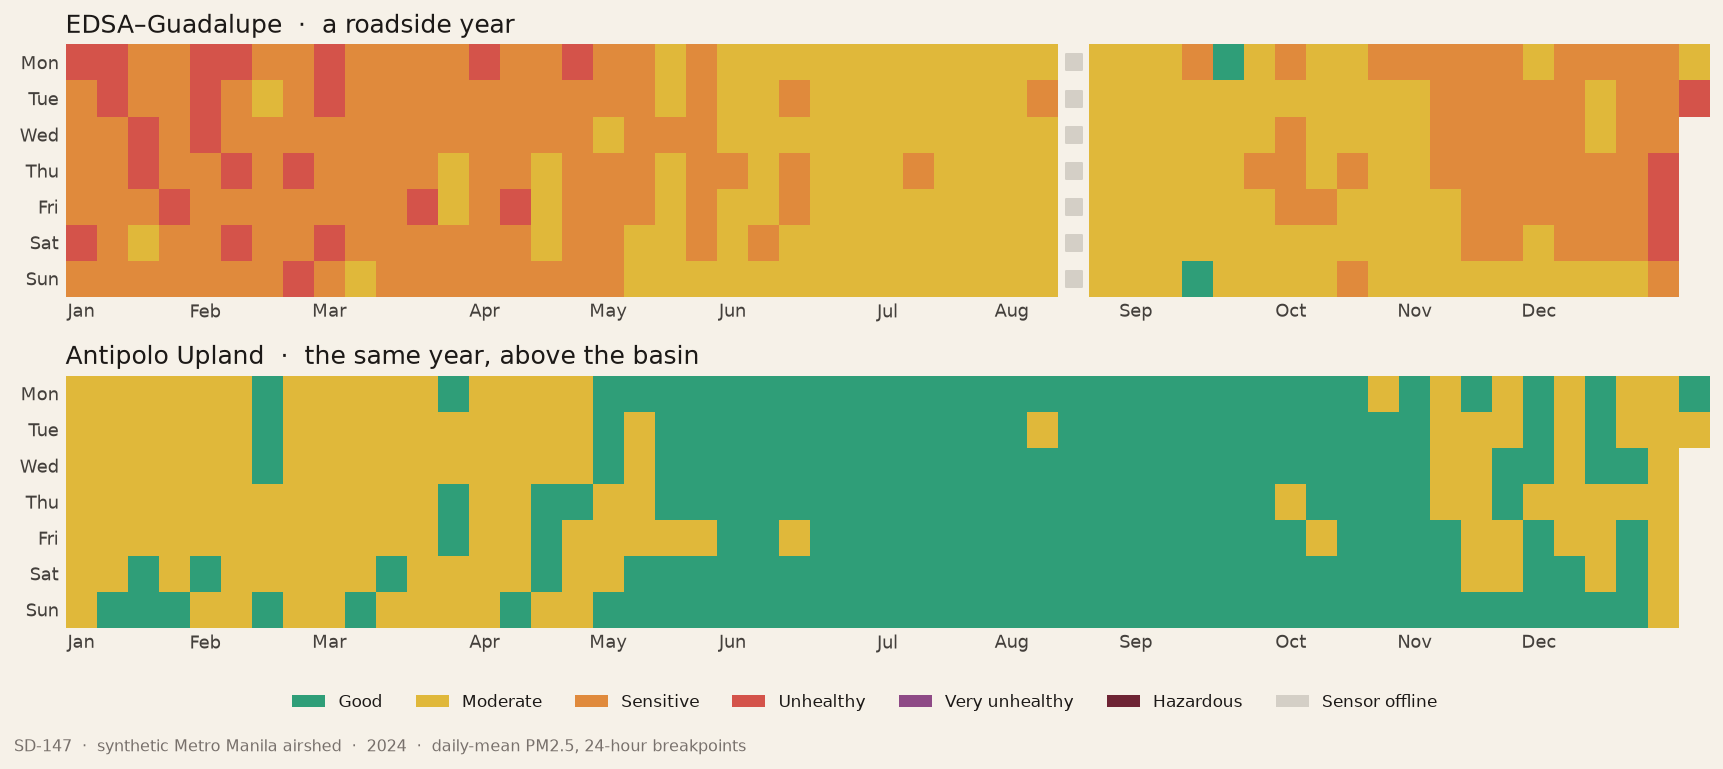

In [5]:
calendars(tables["readings"]);


EDSA spends the dry months in orange and red, and only really breathes during the wet season. Antipolo, on the ridge east of the basin, stays green through the same months. The two red edges of the EDSA year are the firework nights. The grey column in August is the frozen sensor, not a clean week. The teal stripe in the middle of September is the typhoon.


## Where the year was dirtiest

Color is the annual mean of PM2.5. On the map, a larger marker opened more alert episodes. The ranking on the right is that same mean, with the name attached.


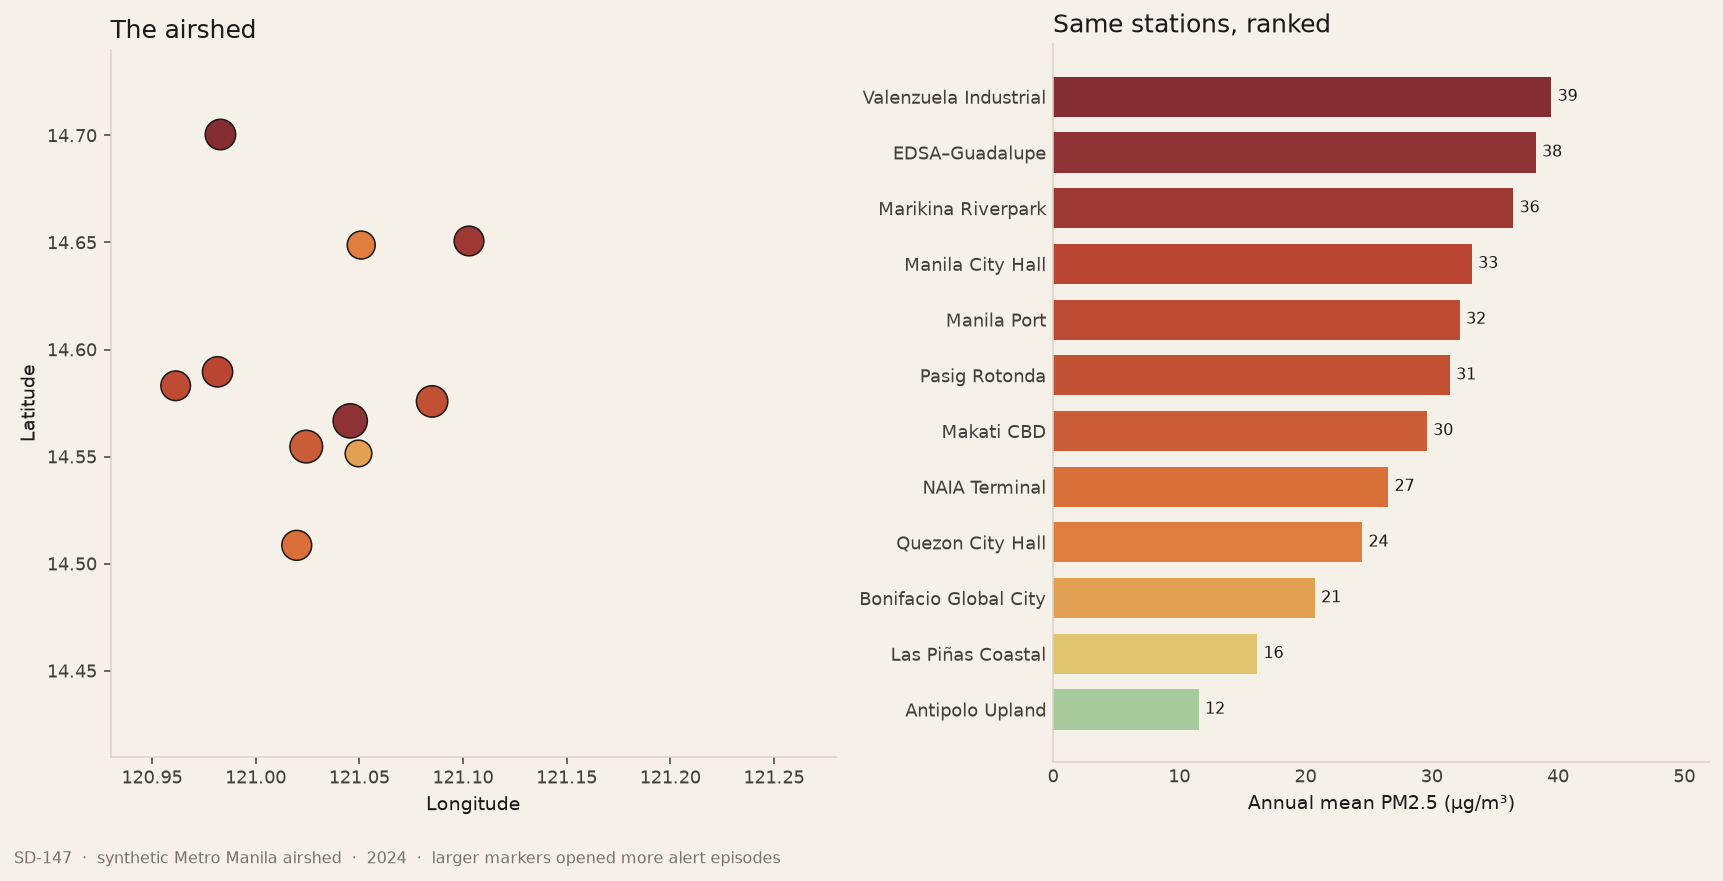

In [6]:
station_map(tables["stations"], tables["readings"], tables["alerts"]);


The dirty sites are the ones sitting in traffic or in industry: Valenzuela, EDSA, Marikina's valley, the port, Manila. Bonifacio Global City and Las Piñas sit cooler. Antipolo is the pale mark on the eastern edge. Same airshed, three times the particles once you drop off the ridge and onto EDSA.


## The shape of a day

Median hour, with the middle half of hours shaded. Black is an EDSA weekday, teal is an EDSA Sunday, clay is an Antipolo weekday.


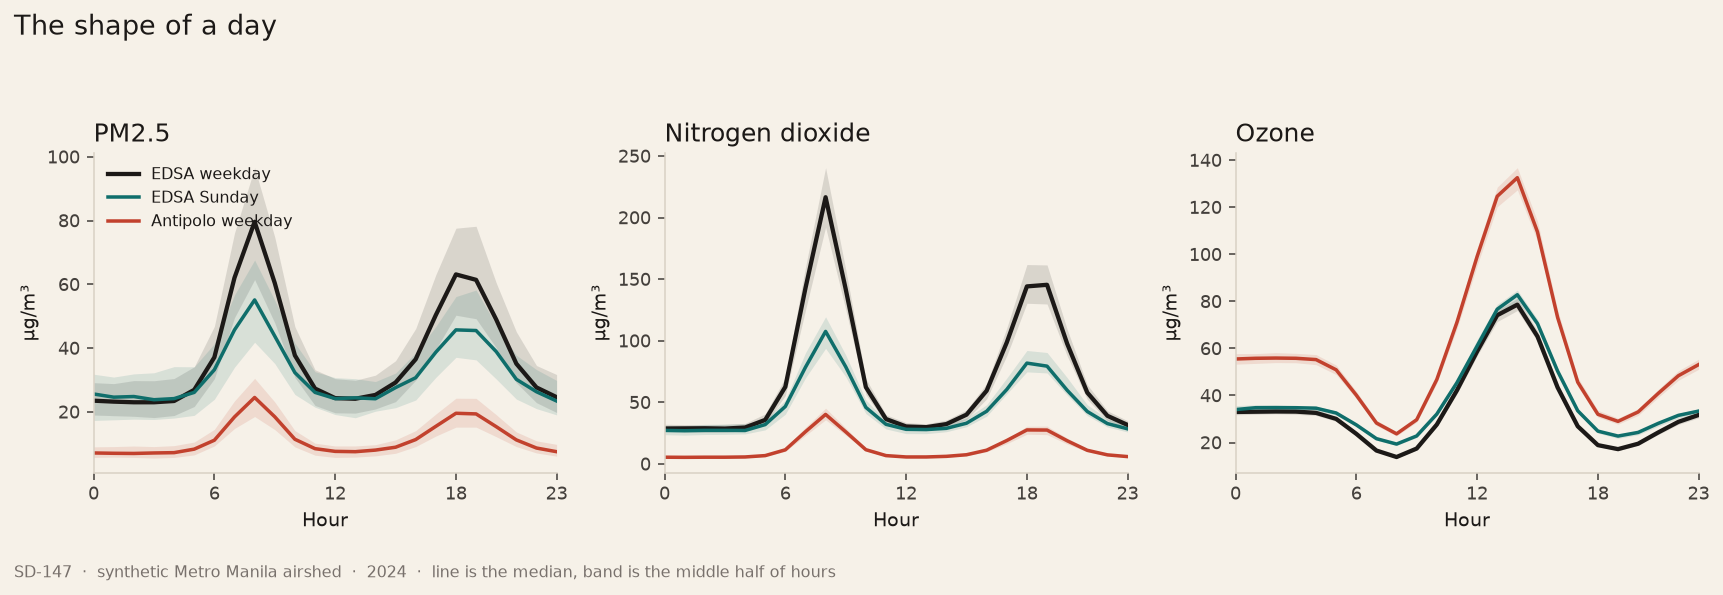

In [7]:
diurnal(tables["readings"]);


Particles and NO2 belong to the commute. Both peaks shrink on Sunday, and both nearly disappear at Antipolo. Ozone belongs to the early afternoon, and it is highest at the station with the least NO2. A morning of exhaust and an afternoon of sunlight are two different pollutants. A dashboard that draws one line for "air quality" will hide that.


## Four things that are not ordinary

The gold band is the planted window. On the dust panel, teal is PM2.5 and black is PM10.


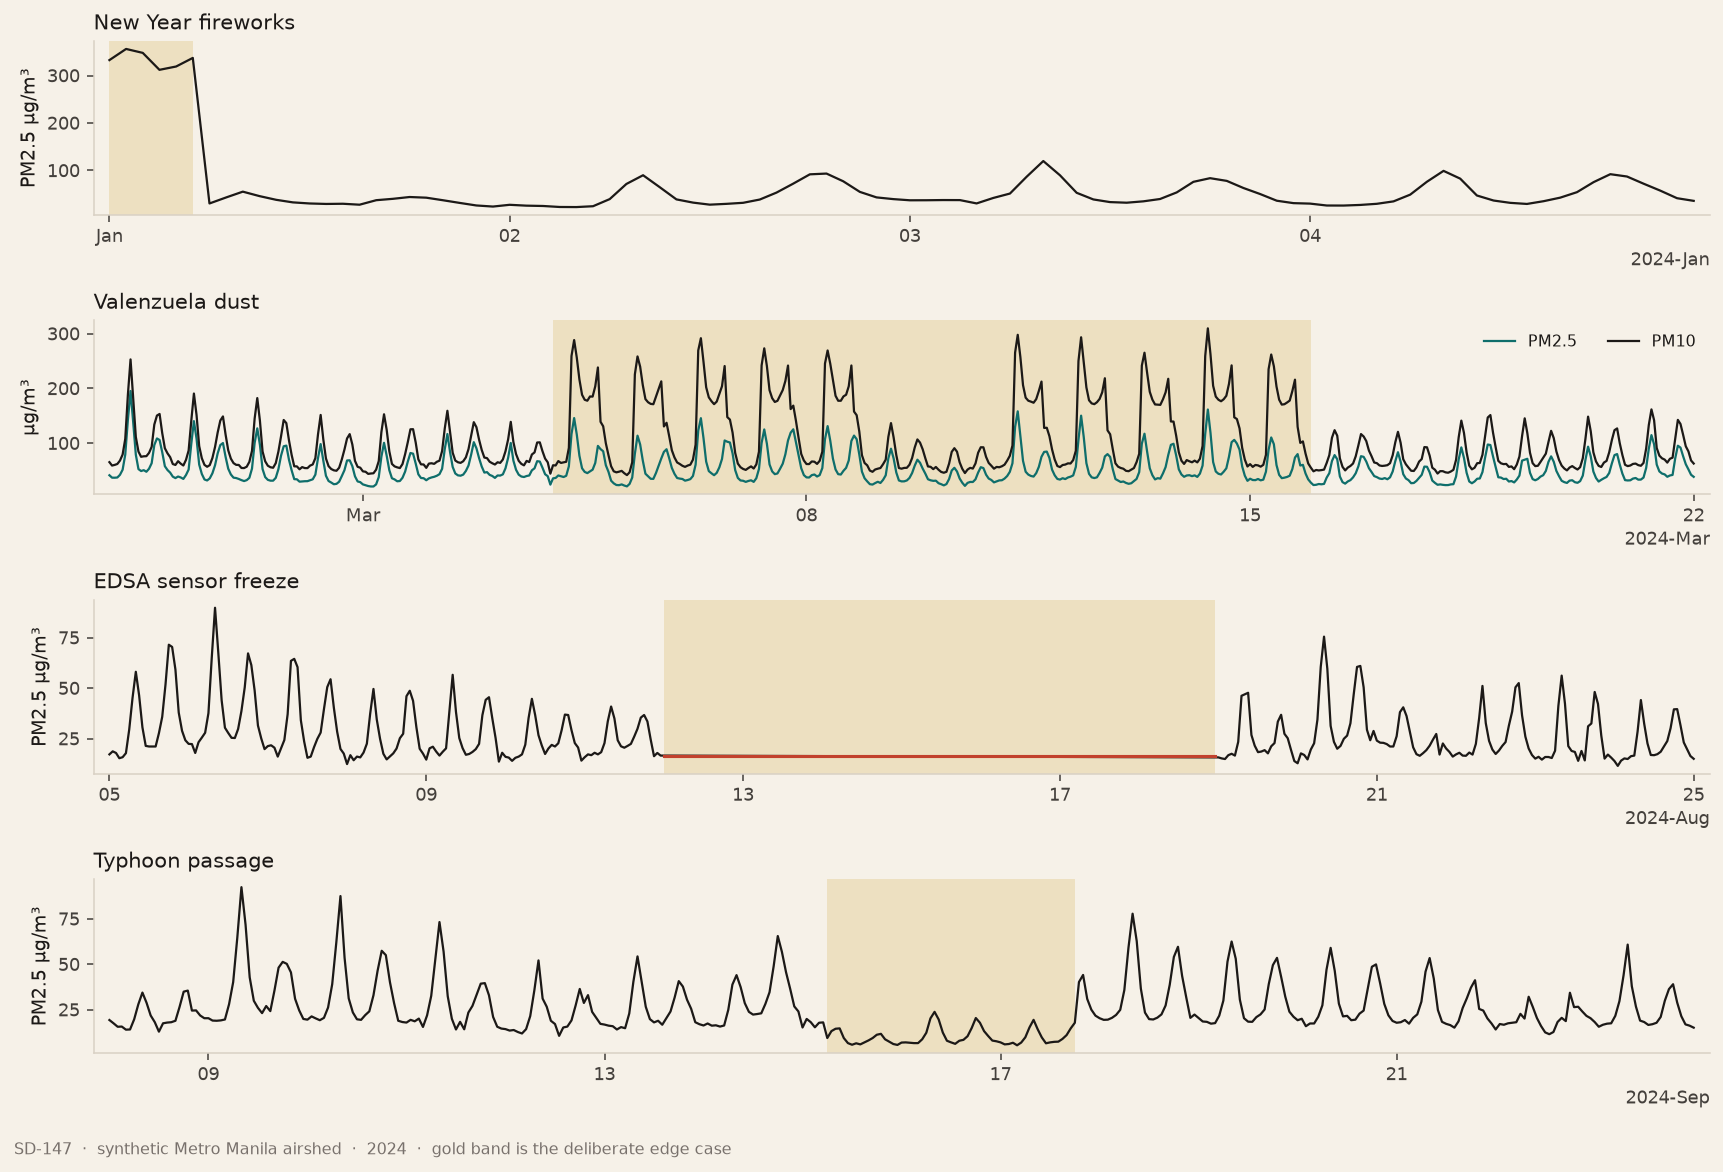

In [8]:
episodes(tables["readings"], tables["weather_proxies"]);


The firework morning is a wall, not a rush hour: several hundred micrograms, then a normal diurnal by the next dawn. At Valenzuela the fine fraction barely notices the work crew, while PM10 doubles and triples on weekday afternoons and rests on the weekend. In August the EDSA particle channel goes flat and red for a week, then picks up the commute as if nothing happened. The typhoon knocks the peaks down and keeps them down until the wind eases. Anyone averaging August without reading `quality_flag` will call that week the cleanest of the year.


## Dry season, written in the grid

Monthly mean PM2.5. Stations run north to south, which is not the same order as how dirty they are. Antipolo sits in the middle of the list and stays the light row.


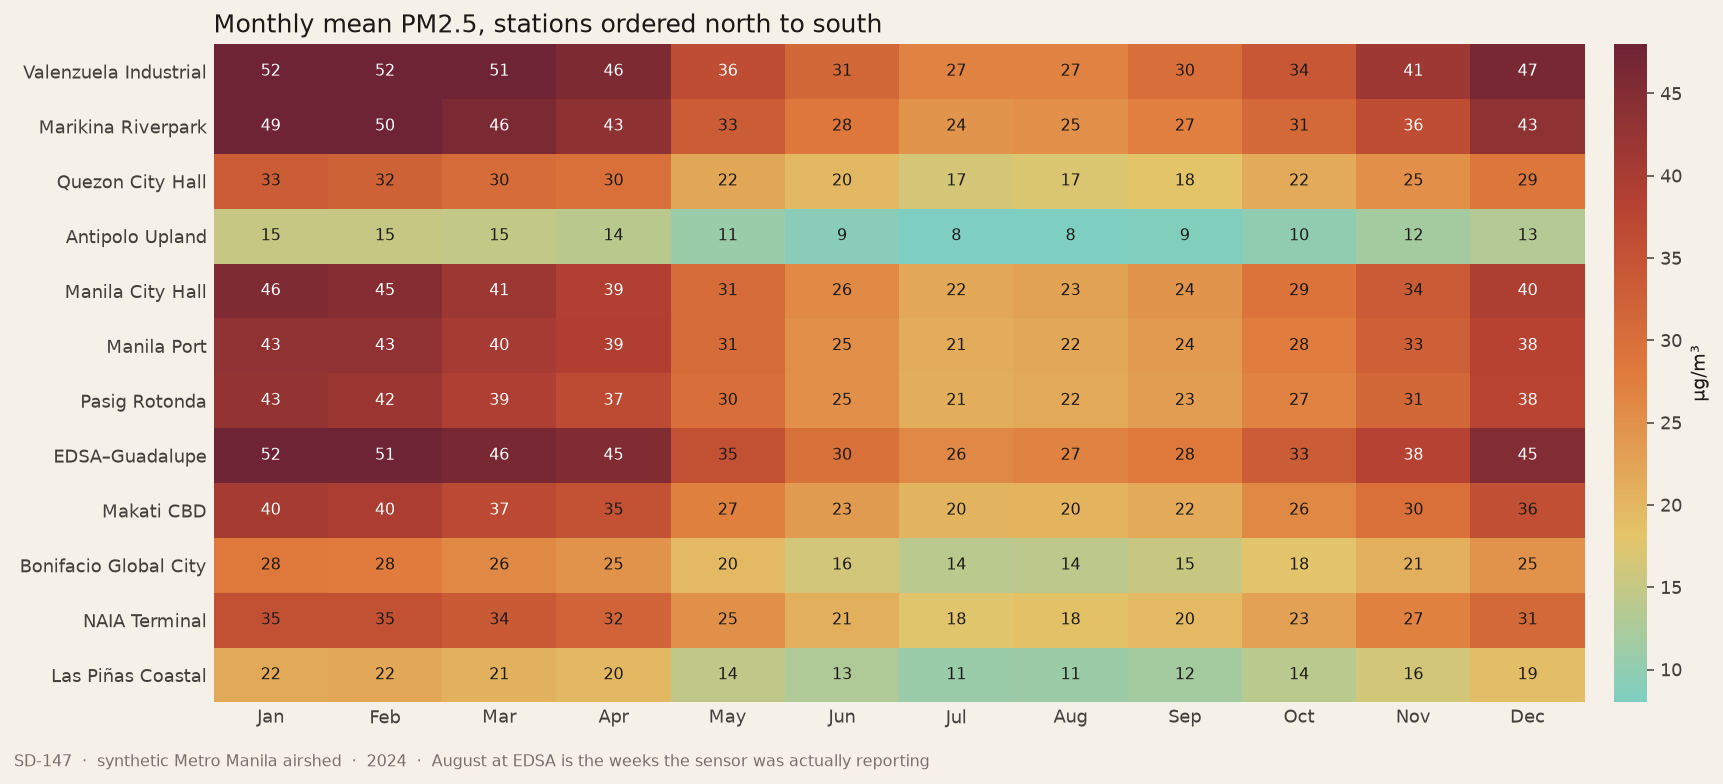

In [9]:
season_grid(tables["readings"], tables["stations"]);


January through April is the dark block on every roadside and industrial row. June through September cools the whole airshed, including the stations that never get truly clean. December climbs back. August at EDSA is computed only from the hours the sensor was actually moving.


## Rain, then wind

Daily mean PM2.5 against the rain that fell that day, pooled across stations. The white or dark tick on each bar is the median. The right-hand panel is the same days against the wind.


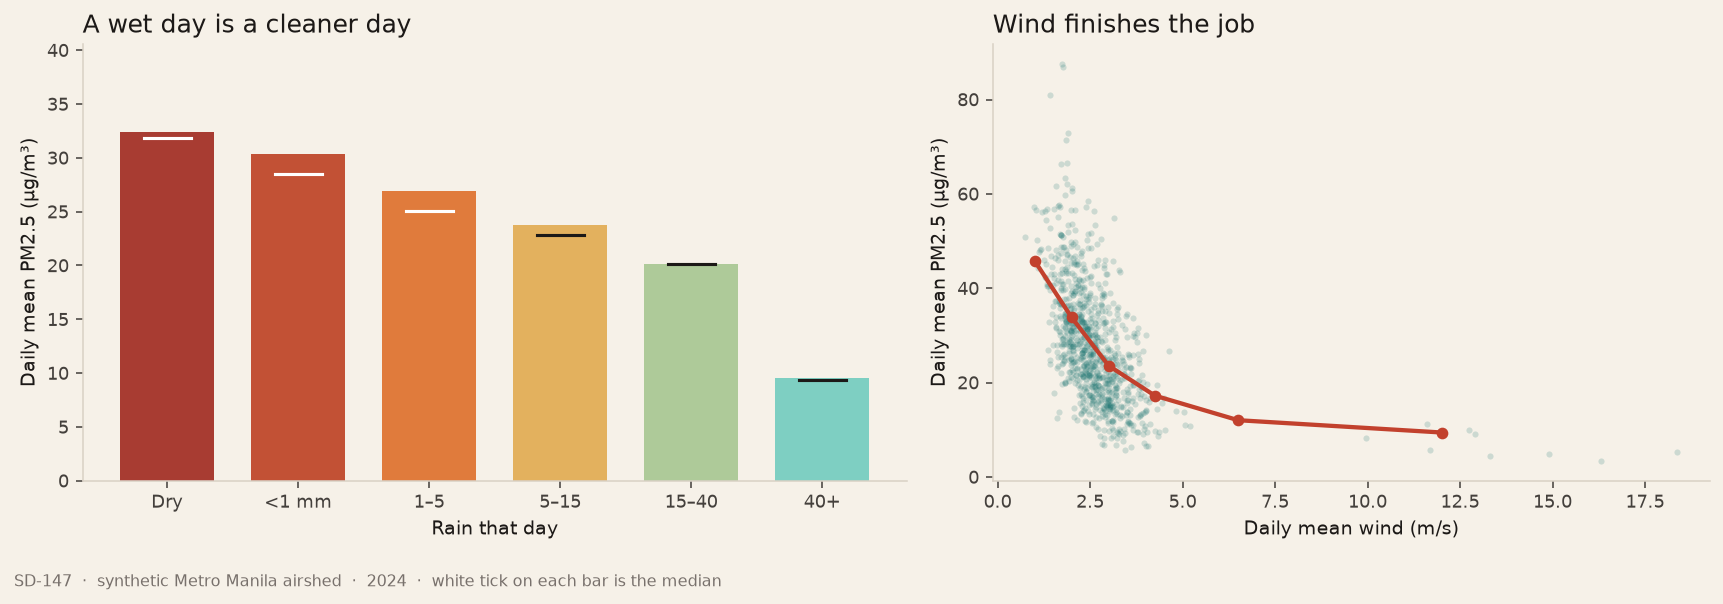

In [10]:
washout(tables["readings"], tables["weather_proxies"]);


A dry day sits near 32 µg/m³. A day with 40 mm or more sits near 10. Wind does the rest of the work and then flattens: past about 6 m/s there is not much particle left to remove. That flattening is also why the typhoon does not zero the instruments.


## What these tables will sit still for

- Rank stations and months against the 24-hour PM2.5 breakpoints, and separate a dry-season pattern from a broken instrument.
- Compare the weekday commute in PM2.5 and NO2 with Sunday, and with the afternoon ozone peak at Antipolo.
- Estimate how many micrograms a rainy day and a windy day are worth.
- Count alert episodes, how long they last, and which pollutant is the driver. Most of them should be PM2.5, lasting hours rather than a single timestamp.
- Test a dashboard against three traps: firework nights that are not traffic, a construction site that inflates only the coarse fraction, and a flat week that must not be averaged in.

Run this notebook from the repo root. The CSVs land in `data/`. The specification you would hand a reviewer is `assumptions.md`.
